In [ ]:
from google.colab import files
import pandas as pd

# This will prompt you to select the file from your computer
uploaded = files.upload()

# Get the uploaded filename automatically
file_path = list(uploaded.keys())[0]

# Load the Excel file
xls = pd.ExcelFile(file_path)
df_raw = pd.read_excel(xls, sheet_name='Sheet 1 - traffic_data-organic.', header=1)
df_raw.head()



Saving traffic_data-organic.Positions-us-20250126-2025-01-27T11_19_53Z copy.xls to traffic_data-organic.Positions-us-20250126-2025-01-27T11_19_53Z copy.xls


,Keyword,Keyword ID,Position,Previous Position,Search Volume,Keyword Difficulty,CPC,Traffic,Traffic (%),Traffic Cost,Competition,Number of Results,Trends,Timestamp,SERP Features by Keyword,Keyword Intents,Position Type
0,c,1,2,2,1830000,100.0,0.50,27450,1.91,13725,0.01,25270000000,"[20,20,54,20,29,24,20,20,24,24,36,24]",2025-01-26,"Knowledge panel, Sitelinks, Reviews, Video, Im...",informational,Things to know
1,github,2,1,0,823000,100.0,2.34,10699,0.74,25035,0.01,576000000,"[54,54,54,54,81,54,36,36,54,54,54,54]",2025-01-26,"Knowledge panel, Image pack, Sitelinks, Review...",navigational,People also ask
2,six sigma,3,1,1,40500,78.0,1.74,10044,0.69,17476,0.24,153000000,"[54,81,81,81,100,66,66,54,66,66,66,66]",2025-01-26,"Knowledge panel, Sitelinks, Reviews, Video, Fe...",informational,Organic
3,salesforce,4,1,1,550000,100.0,8.34,7150,0.49,59631,0.10,224000000,"[36,55,45,45,45,55,45,55,55,45,45,45]",2025-01-26,"Knowledge panel, Sitelinks, Reviews, Video, Pe...",navigational,People also ask
4,simplilearn,5,1,1,8100,67.0,2.31,6480,0.45,14968,0.14,4270000,"[44,54,44,54,44,66,54,54,54,54,81,44]",2025-01-26,"Sitelinks, Reviews, Tweet, Video, People also ...",navigational,Organic


In [ ]:
import numpy as np
import ast

# 1. Load data
file_path = 'traffic_data-organic.Positions-us-20250126-2025-01-27T11_19_53Z copy.xls'
xls = pd.ExcelFile(file_path)
df = pd.read_excel(xls, sheet_name='Sheet 1 - traffic_data-organic.', header=1)

print(f"Initial shape: {df.shape}")

# 2. Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing exact duplicates: {df.shape}")

# 3. Clean whitespace on text columns
text_cols = ['Keyword', 'Keyword Intents', 'Position Type', 'SERP Features by Keyword']
for col in text_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().replace({'nan': np.nan, 'None': np.nan})

# 4. Handle Missing Values
# - Impute numerical metrics (Keyword Difficulty) with median
df['Keyword Difficulty'] = df['Keyword Difficulty'].fillna(df['Keyword Difficulty'].median())

# - Impute categorical columns with explicit placeholders
df['Keyword Intents'] = df['Keyword Intents'].fillna('unknown')
df['SERP Features by Keyword'] = df['SERP Features by Keyword'].fillna('None')

# 5. Correct Data Types
# - Convert Timestamp to datetime
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')

# - Parse Trends string into actual Python lists
def parse_trends(val):
    try:
        return ast.literal_eval(val) if isinstance(val, str) else val
    except (ValueError, SyntaxError):
        return []

df['Trends_List'] = df['Trends'].apply(parse_trends)

# 6. Add Position Change Feature
df['Position_Change'] = df['Previous Position'] - df['Position']

# Verification
print("\n--- Cleaning Complete ---")
print("Remaining Missing Values:")
print(df.isnull().sum())
print("\nCleaned Data Summary:")
df.info()


Initial shape: (30000, 17)
Shape after removing exact duplicates: (29991, 17)

--- Cleaning Complete ---
Remaining Missing Values:
Keyword                     0
Keyword ID                  0
Position                    0
Previous Position           0
Search Volume               0
Keyword Difficulty          0
CPC                         0
Traffic                     0
Traffic (%)                 0
Traffic Cost                0
Competition                 0
Number of Results           0
Trends                      0
Timestamp                   0
SERP Features by Keyword    0
Keyword Intents             0
Position Type               0
Trends_List                 0
Position_Change             0
dtype: int64

Cleaned Data Summary:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29991 entries, 0 to 29990
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Keyword                  

/tmp/ipykernel_511/727173394.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_traffic, x='Traffic', y='Keyword', palette='viridis')
/tmp/ipykernel_511/727173394.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_intents.values, y=top_intents.index, palette='mako')


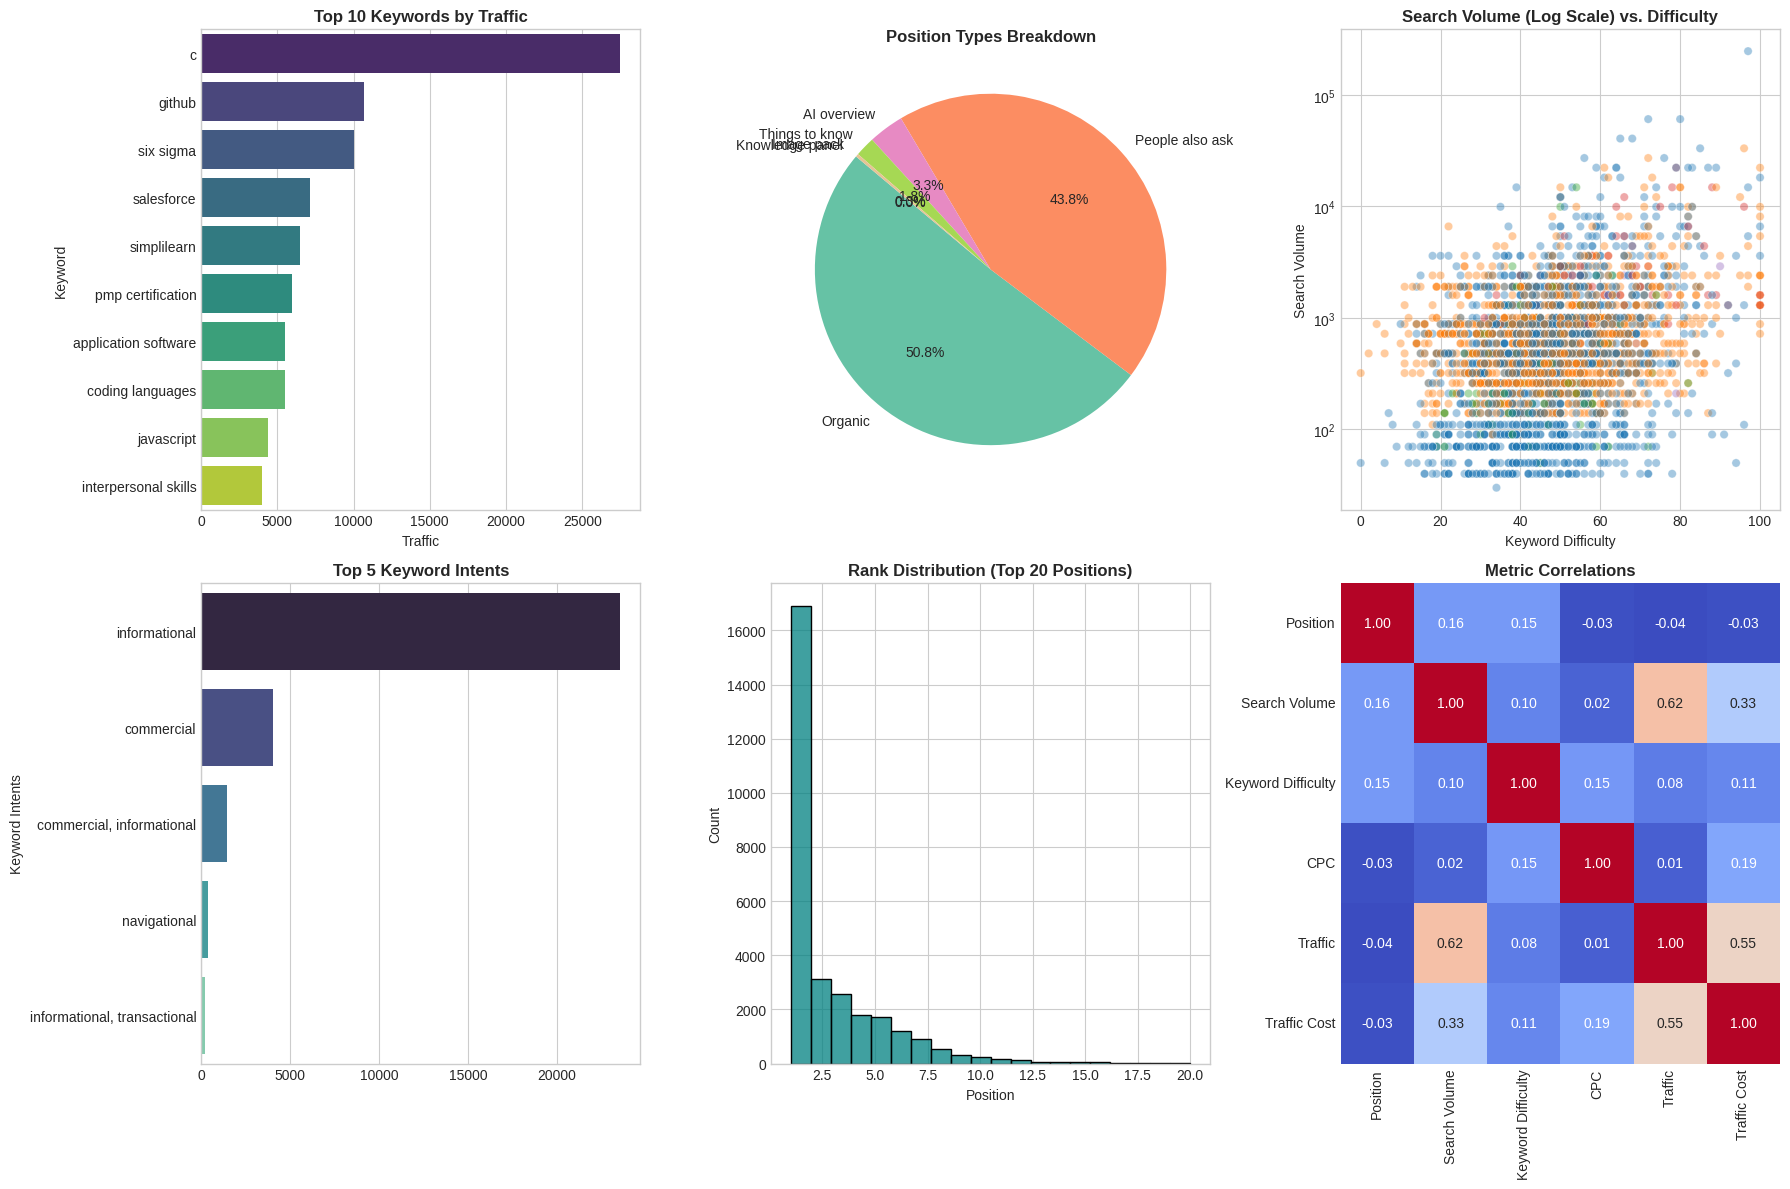

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# If df was already cleaned in the previous step, work directly with a copy
df_clean = df.copy()

# Fill missing values if not already handled
df_clean['Keyword Difficulty'] = df_clean['Keyword Difficulty'].fillna(df_clean['Keyword Difficulty'].median())
df_clean['Keyword Intents'] = df_clean['Keyword Intents'].fillna('Unknown')
df_clean['Position Type'] = df_clean['Position Type'].fillna('Unknown')

# Set plotting canvas
plt.figure(figsize=(18, 12))
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Top 10 Keywords by Traffic
plt.subplot(2, 3, 1)
top_traffic = df_clean.sort_values(by='Traffic', ascending=False).head(10)
sns.barplot(data=top_traffic, x='Traffic', y='Keyword', palette='viridis')
plt.title('Top 10 Keywords by Traffic', fontweight='bold')

# 2. Position Type Distribution
plt.subplot(2, 3, 2)
df_clean['Position Type'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=140, cmap='Set2')
plt.title('Position Types Breakdown', fontweight='bold')
plt.ylabel('')

# 3. Keyword Difficulty vs Search Volume
plt.subplot(2, 3, 3)
sample_df = df_clean.sample(min(3000, len(df_clean)), random_state=42)
sns.scatterplot(data=sample_df, x='Keyword Difficulty', y='Search Volume', alpha=0.4, hue='Position Type', legend=False)
plt.yscale('log')
plt.title('Search Volume (Log Scale) vs. Difficulty', fontweight='bold')

# 4. Top 5 Keyword Intents
plt.subplot(2, 3, 4)
top_intents = df_clean['Keyword Intents'].value_counts().head(5)
sns.barplot(x=top_intents.values, y=top_intents.index, palette='mako')
plt.title('Top 5 Keyword Intents', fontweight='bold')

# 5. Rank Distribution (Top 20 Positions)
plt.subplot(2, 3, 5)
sns.histplot(df_clean[df_clean['Position'] <= 20]['Position'], bins=20, kde=False, color='teal')
plt.title('Rank Distribution (Top 20 Positions)', fontweight='bold')

# 6. Feature Correlation Matrix
plt.subplot(2, 3, 6)
corr = df_clean[['Position', 'Search Volume', 'Keyword Difficulty', 'CPC', 'Traffic', 'Traffic Cost']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=False)
plt.title('Metric Correlations', fontweight='bold')

plt.tight_layout()
plt.show()



Pearson Correlation (Search Volume vs. Traffic): 0.6235
Spearman Rank Correlation (Search Volume vs. Traffic): 0.4641


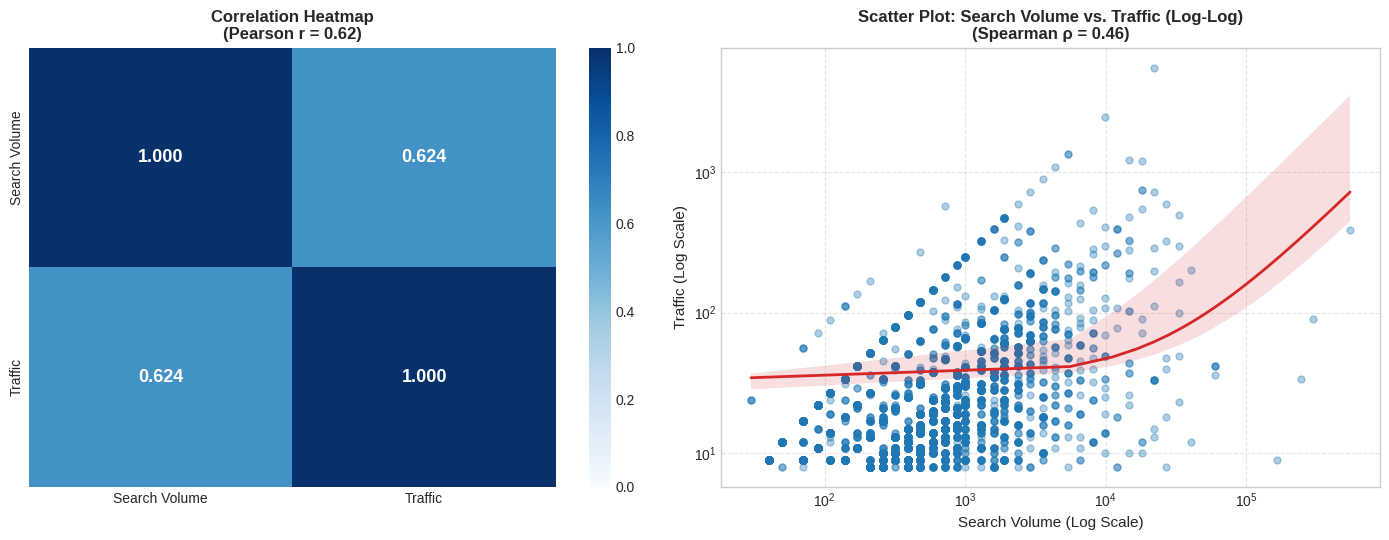

In [ ]:
# 1. Calculate Correlation Coefficients
var1 = 'Search Volume'
var2 = 'Traffic'

pearson_val = df[var1].corr(df[var2], method='pearson')
spearman_val = df[var1].corr(df[var2], method='spearman')

print(f"Pearson Correlation ({var1} vs. {var2}): {pearson_val:.4f}")
print(f"Spearman Rank Correlation ({var1} vs. {var2}): {spearman_val:.4f}")

# 2. Plot Heatmap & Scatter Plot Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot 1: Heatmap
corr_matrix = df[[var1, var2]].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='Blues', ax=axes[0],
            annot_kws={'size': 13, 'weight': 'bold'}, vmin=0, vmax=1)
axes[0].set_title(f'Correlation Heatmap\n(Pearson r = {pearson_val:.2f})', fontsize=12, fontweight='bold')

# Subplot 2: Scatter Plot with Regression Fit (Log-Log Scale)
sample_df = df.sample(min(5000, len(df)), random_state=42)
sns.regplot(data=sample_df, x=var1, y=var2,
            scatter_kws={'alpha': 0.35, 'color': '#1f77b4', 's': 25},
            line_kws={'color': '#d62728', 'linewidth': 2}, ax=axes[1])

axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title(f'Scatter Plot: {var1} vs. {var2} (Log-Log)\n(Spearman ρ = {spearman_val:.2f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel(f'{var1} (Log Scale)', fontsize=11)
axes[1].set_ylabel(f'{var2} (Log Scale)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


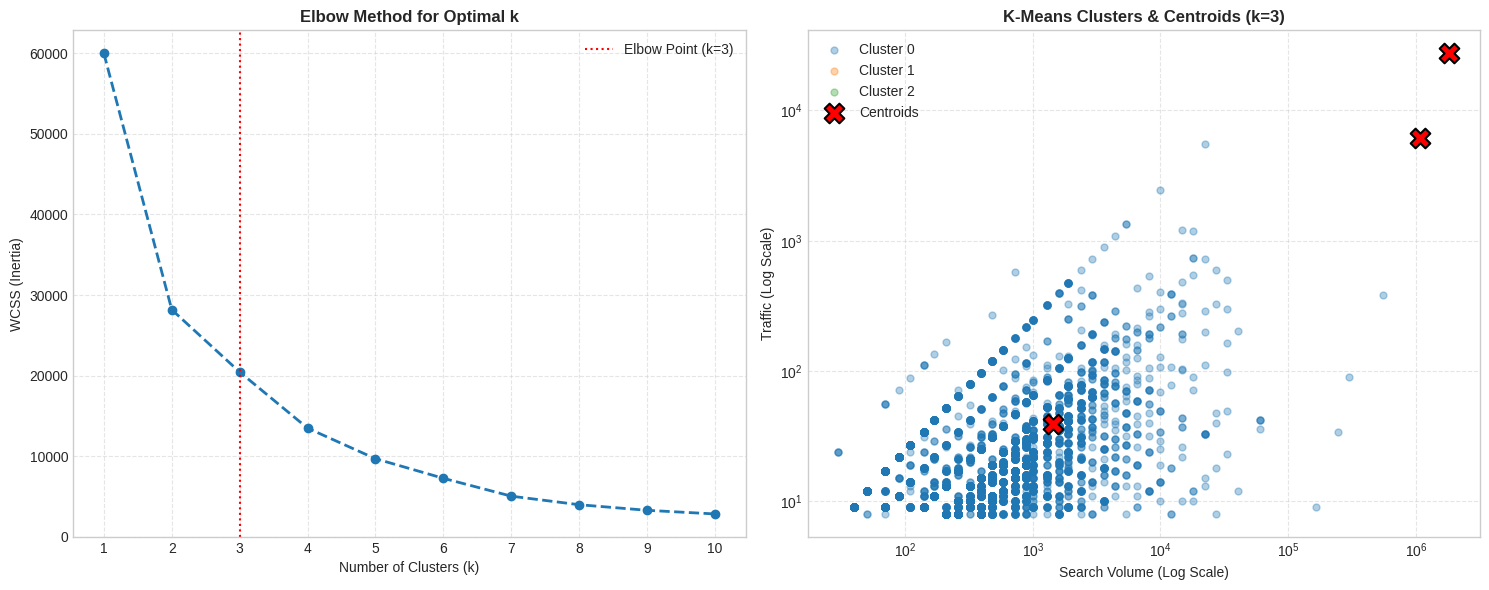

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Feature Selection & Standardization
X = df[['Search Volume', 'Traffic']].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Elbow Method (WCSS calculation for k=1 to 10)
k_range = range(1, 11)
wcss = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# 3. Fit K-Means with Optimal k=3
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

# 4. Extract and Inverse-Transform Centroids to Original Units
centroids_scaled = kmeans_final.cluster_centers_
centroids = scaler.inverse_transform(centroids_scaled)

# 5. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Elbow Curve
axes[0].plot(k_range, wcss, marker='o', linestyle='--', color='#1f77b4', linewidth=2)
axes[0].axvline(x=optimal_k, color='red', linestyle=':', label=f'Elbow Point (k={optimal_k})')
axes[0].set_title('Elbow Method for Optimal k', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('WCSS (Inertia)')
axes[0].set_xticks(k_range)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Cluster Scatter Plot with Centroids
sample_plot = df.sample(min(5000, len(df)), random_state=42)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for c in range(optimal_k):
    pts = sample_plot[sample_plot['Cluster'] == c]
    axes[1].scatter(pts['Search Volume'], pts['Traffic'], label=f'Cluster {c}', alpha=0.35, s=25, color=colors[c])

# Plot Centroid X markers
axes[1].scatter(centroids[:, 0], centroids[:, 1], s=200, c='red', marker='X', edgecolor='black', linewidth=1.5, label='Centroids')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title(f'K-Means Clusters & Centroids (k={optimal_k})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Search Volume (Log Scale)')
axes[1].set_ylabel('Traffic (Log Scale)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Select the 2 correlated features
X = df[['Search Volume', 'Traffic']]

# 2. Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Apply K-Means (k=3 from the Elbow method)
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# 4. Get the Centroids in original units
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
centroids_df = pd.DataFrame(centroids, columns=['Search Volume', 'Traffic'])
centroids_df.index.name = 'Cluster'

print("--- Cluster Centroids ---")
print(centroids_df)

# 5. View sample results
print("\n--- Clustered Data Sample ---")
print(df[['Keyword', 'Search Volume', 'Traffic', 'Cluster']].head(10))


--- Cluster Centroids ---
         Search Volume       Traffic
Cluster                             
0         1.446725e+03     39.030748
1         1.067667e+06   6132.666667
2         1.830000e+06  27450.000000

--- Clustered Data Sample ---
                Keyword  Search Volume  Traffic  Cluster
0                     c        1830000    27450        2
1                github         823000    10699        1
2             six sigma          40500    10044        0
3            salesforce         550000     7150        1
4           simplilearn           8100     6480        0
5     pmp certification          90500     5973        0
6  application software          22200     5505        0
7      coding languages          22200     5505        0
8            javascript         135000     4387        0
9  interpersonal skills          60500     3993        0
